# Task 57. Exercise on MLP

The linked crash course on Multi-Layer Perceptrons explains the ideas without code.
Each section below shows one of those ideas in code: neurons, activation functions,
layers, data preparation, training with stochastic gradient descent and prediction.

In [1]:
# ===== 1. Neurons: weights, bias and activation =====
import numpy as np

inputs = np.array([0.5, -1.2, 3.0])
weights = np.array([0.4, 0.7, -0.2])
bias = 0.1

weighted_sum = np.dot(inputs, weights) + bias
print("Weighted sum:", weighted_sum)

Weighted sum: -1.14


In [2]:
# ===== 2. Activation functions =====
import matplotlib.pyplot as plt

def step(x):
    return np.where(x >= 0, 1, 0)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

print("step:", step(weighted_sum))
print("sigmoid:", sigmoid(weighted_sum))
print("tanh:", tanh(weighted_sum))
print("relu:", relu(weighted_sum))

step: 0
sigmoid: 0.24232036099629517
tanh: -0.814414093765686
relu: 0.0


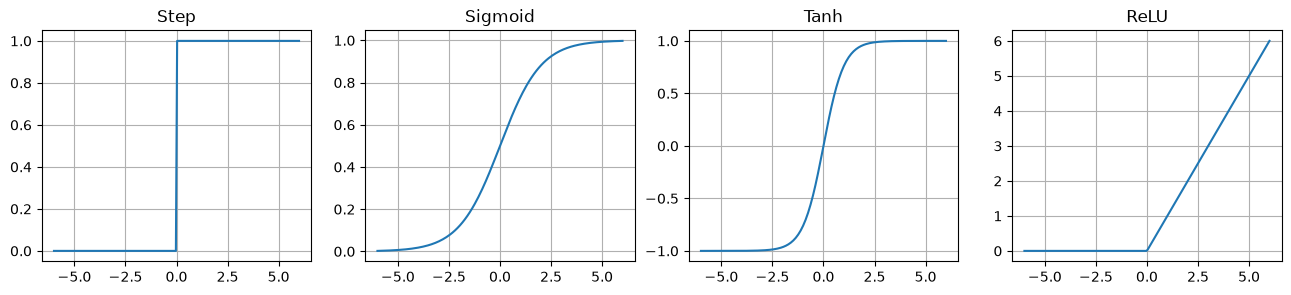

In [3]:
x = np.linspace(-6, 6, 200)
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (name, f) in zip(axes, [('Step', step), ('Sigmoid', sigmoid), ('Tanh', tanh), ('ReLU', relu)]):
    ax.plot(x, f(x))
    ax.set_title(name)
    ax.grid(True)
plt.show()

In [4]:
# ===== 3. Networks of neurons: input, hidden and output layers =====
# a forward pass through a small network: 4 inputs -> 5 hidden -> 3 outputs
rng = np.random.default_rng(0)

x_sample = rng.normal(size=4)                     # input (visible) layer
W1, b1 = rng.normal(size=(4, 5)), np.zeros(5)     # hidden layer
W2, b2 = rng.normal(size=(5, 3)), np.zeros(3)     # output layer

hidden = relu(x_sample @ W1 + b1)
scores = hidden @ W2 + b2

def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

print("Hidden layer:", hidden)
print("Output probabilities:", softmax(scores))

Hidden layer: [0.         0.         0.         0.15387979 0.24091362]
Output probabilities: [0.28958379 0.31248039 0.39793582]


In [5]:
# ===== 4. Training networks: data preparation =====
# Iris dataset: 4 numeric features, 3 classes
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# scale the inputs so all features have a similar range
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


In [6]:
# one-hot encode the class labels (one output neuron per class)
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, 3)
y_test_cat = to_categorical(y_test, 3)
print(y_train[:5])
print(y_train_cat[:5])

[0 2 1 0 1]
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [7]:
# ===== Building the MLP with Keras =====
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

tf.random.set_seed(42)

model = Sequential([
    Input(shape=(4,)),
    Dense(8, activation='relu'),     # hidden layer
    Dense(8, activation='relu'),     # hidden layer
    Dense(3, activation='softmax')   # output layer
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139 (556.00 B)

 Trainable params: 139 (556.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
# ===== Stochastic gradient descent and weight updates =====
# batch_size=1 updates the weights after every example (online learning)
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
              loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_cat, epochs=50, batch_size=1, verbose=0)
print("Final training accuracy:", history.history['accuracy'][-1])

Final training accuracy: 0.9833333492279053


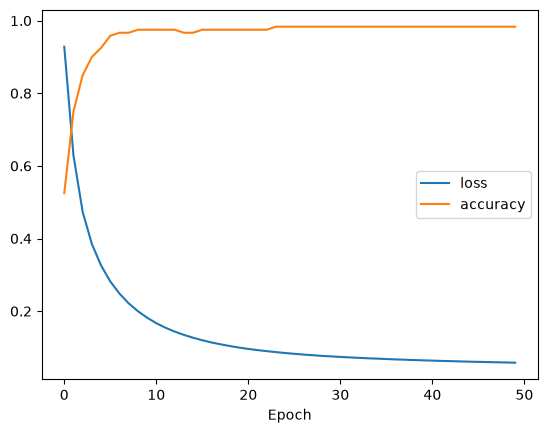

In [9]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['accuracy'], label='accuracy')
plt.xlabel('Epoch')
plt.legend();

In [10]:
# ===== Prediction =====
loss, acc = model.evaluate(X_test, y_test_cat, verbose=0)
print("Test accuracy:", acc)

probabilities = model.predict(X_test[:5], verbose=0)
print(np.round(probabilities, 3))
print("Predicted classes:", probabilities.argmax(axis=1))
print("Actual classes:   ", y_test[:5])

Test accuracy: 0.9666666388511658


[[1.    0.    0.   ]
 [0.008 0.203 0.789]
 [0.048 0.927 0.025]
 [0.031 0.944 0.025]
 [1.    0.    0.   ]]
Predicted classes: [0 2 1 1 0]
Actual classes:    [0 2 1 1 0]
